# Analisis

## Import y rutas

In [195]:
from pathlib import Path
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_validate
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

In [189]:
ROOT_DIR = Path.cwd().parent
RAW_DATA_DIR = ROOT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = ROOT_DIR / "data" / "processed"

RAW_KUEPA_FILE = RAW_DATA_DIR / "Prueba_Tecnica_Analista_Datos_EFE.xlsx" 
PROCESSED_DATA_INCRIPCION = PROCESSED_DATA_DIR / "Inscritos.csv"
PROCESSED_DATA_ACTIVIDAD = PROCESSED_DATA_DIR / "Actividad.csv"
PROCESSED_DATA_EMPLEABILIDAD = PROCESSED_DATA_DIR / "Empleabilidad.csv"

SPLIT_ARTIFACTS = PROCESSED_DATA_DIR / "split_artifacts.pkl"
LR_MODEL = ROOT_DIR / "models" / "lr_best_model.pkl"


## Carga

In [84]:
df_inscritos=pd.read_csv(PROCESSED_DATA_INCRIPCION)
print(f"Dataset loaded with {df_inscritos.shape[0]} rows and {df_inscritos} columns")

df_actividad = pd.read_csv(PROCESSED_DATA_ACTIVIDAD)
print(f"Dataset loaded with {df_inscritos.shape[0]} rows and {df_inscritos.shape[1]} columns")



Dataset loaded with 722 rows and     id_inscrito   documento                     nombre genero  edad  \
0      KP-00670  1081624071        Camila Ortiz Pineda      F  20.0   
1      KP-00557  1060304725        Angie Ramírez Gómez      F  25.0   
2      KP-00462  1086701248      Cristian Ortiz Torres      F  27.0   
3      KP-00590  1048716090       Steven López Ramírez      F  30.0   
4      KP-00165  1099940210           Juan Muñoz Gómez      F  18.0   
..          ...         ...                        ...    ...   ...   
717    KP-00561  1036069609         Felipe Torres Díaz      F  30.0   
718    KP-00125  1039613958    Laura Quintero Quintero      M  24.0   
719    KP-00643  1084447247        Jhon Rojas Quintero      F  27.0   
720    KP-00484  1090058234        Steven Moreno López      F  23.0   
721    KP-00124  1084632920  Camila Hernández Quintero      F  21.0   

           ciudad           proyecto canal_convocatoria gestor  estrato  \
0          Bogotá      Impulsa Mujer   

In [85]:
df_actividad['fecha_primer_ingreso'] = pd.to_datetime(
    df_actividad['fecha_primer_ingreso'],
    errors='coerce'
)
df_actividad['ultima_conexion'] = pd.to_datetime(
    df_actividad['ultima_conexion'],
    errors='coerce'
)
df_inscritos['fecha_inscripcion'] = pd.to_datetime(
    df_inscritos['fecha_inscripcion'],
    errors='coerce'
)

In [86]:
print(df_actividad[['fecha_primer_ingreso','ultima_conexion']].dtypes)

fecha_primer_ingreso    datetime64[ns]
ultima_conexion         datetime64[ns]
dtype: object


In [87]:
df_inscritos.head()


,id_inscrito,documento,nombre,genero,edad,ciudad,proyecto,canal_convocatoria,gestor,estrato,fecha_inscripcion,correo,celular
0,KP-00670,1081624071,Camila Ortiz Pineda,F,20.0,Bogotá,Impulsa Mujer,Redes sociales,G04,2,2026-02-03,camila7001@outlook.com,3.188693e+09
1,KP-00557,1060304725,Angie Ramírez Gómez,F,25.0,Bogotá,Impulsa Mujer,Redes sociales,G05,1,2026-02-04,angie5826@gmail.com,3.055349e+09
2,KP-00462,1086701248,Cristian Ortiz Torres,F,27.0,Bogotá,Talento Digital,Redes sociales,G05,2,2026-02-04,cristian5126@outlook.com,3.678766e+09
3,KP-00590,1048716090,Steven López Ramírez,F,30.0,Barranquilla,Impulsa Mujer,Aliado,G03,2,2026-02-04,steven3015@hotmail.com,3.955668e+09
4,KP-00165,1099940210,Juan Muñoz Gómez,F,18.0,Cali,Ruta Empleo Joven,Redes sociales,G03,1,2026-02-04,juan9400@gmail.com,3.746909e+09


In [88]:
print("---------------Tipos de datos y valores NaN-----------------")
summary = pd.DataFrame({
    "Variable": df_inscritos.columns,
    "Tipp": df_inscritos.dtypes.values,
    "NaN": df_inscritos.isna().sum().values,
    "Unicos": df_inscritos.nunique().values
})

print(summary)

---------------Tipos de datos y valores NaN-----------------
              Variable            Tipp  NaN  Unicos
0          id_inscrito          object    0     722
1            documento           int64    0     722
2               nombre          object    0     685
3               genero          object    9       3
4                 edad         float64   23      22
5               ciudad          object    0       5
6             proyecto          object    0       4
7   canal_convocatoria          object    0       4
8               gestor          object    0       6
9              estrato           int64    0       4
10   fecha_inscripcion  datetime64[ns]    0     194
11              correo          object    3     719
12             celular         float64    8     714


In [89]:
df_actividad.head()

,id_inscrito,fecha_primer_ingreso,dias_activos_semana1,modulos_completados,porcentaje_avance,ultima_conexion,estado,dias_sin_conexion
0,KP-00224,2026-07-28,4,6,72.1,2026-09-29,Activo,-63.0
1,KP-00347,2026-04-09,4,8,100.0,2026-06-23,Graduado,-75.0
2,KP-00410,2026-08-16,1,2,26.4,2026-09-06,Desertor,-21.0
3,KP-00127,2026-03-11,0,8,100.0,2026-05-29,Graduado,-79.0
4,KP-00503,NaT,1,0,0.0,NaT,Desertor,NaN


In [90]:

df_actividad.drop(labels='dias_sin_conexion', axis=1,  inplace=True, errors='raise')


In [91]:
print("---------------Tipos de datos y valores NaN-----------------")
summary = pd.DataFrame({
    "Variable": df_actividad.columns,
    "Tipp": df_actividad.dtypes.values,
    "NaN": df_actividad.isna().sum().values,
    "Unicos": df_actividad.nunique().values
})

print(summary)

---------------Tipos de datos y valores NaN-----------------
               Variable            Tipp  NaN  Unicos
0           id_inscrito          object    0     722
1  fecha_primer_ingreso  datetime64[ns]  110     189
2  dias_activos_semana1           int64    0       6
3   modulos_completados           int64    0       9
4     porcentaje_avance         float64    0     224
5       ultima_conexion  datetime64[ns]  110     192
6                estado          object    0       3


Para facilitar la exploración de los datos se agruparan las variables relevantes en una sola tabla

In [92]:
#Seleccionar las columnas específicas de df_inscritos
cols_inscritos = [
    'id_inscrito', 
    'proyecto', 
    'canal_convocatoria', 
    'genero', 
    'edad', 
    'ciudad', 
    'estrato', 
    'fecha_inscripcion'
]

df_ins_sel = df_inscritos[cols_inscritos].copy()


# Realizar el LEFT JOIN
# Usamos LEFT JOIN para mantener todos los inscritos, incluso si no tienen registro de actividad (serían desertores tempranos)
df_parcial = pd.merge(df_ins_sel, df_actividad, on='id_inscrito', how='left')

# Validación
print(f"Registros en inscritos: {len(df_ins_sel)}")
print(f"Registros tras merge con actividad: {len(df_parcial)}")
print(f"Columnas resultantes: {list(df_parcial.columns)}")

# Mostrar las primeras filas para inspeccionar
df_parcial.head()

Registros en inscritos: 722
Registros tras merge con actividad: 722
Columnas resultantes: ['id_inscrito', 'proyecto', 'canal_convocatoria', 'genero', 'edad', 'ciudad', 'estrato', 'fecha_inscripcion', 'fecha_primer_ingreso', 'dias_activos_semana1', 'modulos_completados', 'porcentaje_avance', 'ultima_conexion', 'estado']


,id_inscrito,proyecto,canal_convocatoria,genero,edad,ciudad,estrato,fecha_inscripcion,fecha_primer_ingreso,dias_activos_semana1,modulos_completados,porcentaje_avance,ultima_conexion,estado
0,KP-00670,Impulsa Mujer,Redes sociales,F,20.0,Bogotá,2,2026-02-03,2026-02-06,5,8,100.0,2026-04-25,Graduado
1,KP-00557,Impulsa Mujer,Redes sociales,F,25.0,Bogotá,1,2026-02-04,2026-02-09,4,8,100.0,2026-04-25,Graduado
2,KP-00462,Talento Digital,Redes sociales,F,27.0,Bogotá,2,2026-02-04,2026-02-16,3,8,100.0,2026-04-25,Graduado
3,KP-00590,Impulsa Mujer,Aliado,F,30.0,Barranquilla,2,2026-02-04,2026-02-04,3,8,100.0,2026-04-27,Graduado
4,KP-00165,Ruta Empleo Joven,Redes sociales,F,18.0,Cali,1,2026-02-04,2026-02-04,2,8,100.0,2026-05-04,Graduado


### Feature engineering

Se decidió crea 3 variables extra para extraer información de las fechas
* Días desde la inscripción al primer ingreso
* Días de dedicación (días entre primera conexión y la ultima)
* Días sin conexión respecto a la fecha de corte 

In [93]:
fecha_corte = pd.to_datetime('2026-09-30')

df_parcial['dias_inscripcion_primer_ingreso'] = (df_parcial['fecha_primer_ingreso'] - df_parcial['fecha_inscripcion']).dt.days

# Dias entre primer ingreso y última conexión (Tiempo de dedicación/ventana activa)
df_parcial['dias_dedicacion_curso'] = (df_parcial['ultima_conexion'] - df_parcial['fecha_primer_ingreso']).dt.days

# Dias sin conexión respecto a la fecha de corte
df_parcial['dias_sin_conexion_corte'] = (fecha_corte - df_parcial['ultima_conexion']).dt.days

df_parcial[['id_inscrito', 'dias_inscripcion_primer_ingreso', 'dias_dedicacion_curso', 'dias_sin_conexion_corte']].head()

,id_inscrito,dias_inscripcion_primer_ingreso,dias_dedicacion_curso,dias_sin_conexion_corte
0,KP-00670,3.0,78.0,158.0
1,KP-00557,5.0,75.0,158.0
2,KP-00462,12.0,68.0,158.0
3,KP-00590,0.0,82.0,156.0
4,KP-00165,0.0,89.0,149.0


In [94]:
df_parcial[['dias_inscripcion_primer_ingreso','dias_dedicacion_curso','dias_sin_conexion_corte']].describe()

,dias_inscripcion_primer_ingreso,dias_dedicacion_curso,dias_sin_conexion_corte
count,612.000000,612.000000,612.000000
mean,2.305556,54.705882,83.240196
std,2.998598,29.064662,58.377737
min,0.000000,-17.000000,0.000000
25%,0.000000,28.000000,27.000000
50%,1.000000,60.000000,81.000000
75%,3.000000,82.000000,127.250000
max,12.000000,89.000000,228.000000


In [95]:
df_parcial[df_parcial['dias_dedicacion_curso']<=0]


,id_inscrito,proyecto,canal_convocatoria,genero,edad,ciudad,estrato,fecha_inscripcion,fecha_primer_ingreso,dias_activos_semana1,modulos_completados,porcentaje_avance,ultima_conexion,estado,dias_inscripcion_primer_ingreso,dias_dedicacion_curso,dias_sin_conexion_corte
259,KP-00597,Impulsa Mujer,Unidad móvil,F,19.0,Bogotá,4,2026-04-13,2026-04-13,1,4,48.8,2026-04-08,Desertor,0.0,-5.0,175.0
285,KP-00608,Impulsa Mujer,Unidad móvil,F,21.0,Medellín,2,2026-04-20,2026-04-21,5,1,14.8,2026-04-09,Desertor,1.0,-12.0,174.0
300,KP-00589,Impulsa Mujer,Redes sociales,F,28.0,Cali,2,2026-04-23,2026-04-28,0,4,48.3,2026-04-24,Desertor,5.0,-4.0,159.0
333,KP-00538,Talento Digital,Redes sociales,F,22.0,Barranquilla,3,2026-05-01,2026-05-02,2,3,40.9,2026-04-15,Desertor,1.0,-17.0,168.0
349,KP-00248,Ruta Empleo Joven,Referido,M,24.0,Bogotá,4,2026-05-07,2026-05-07,0,3,37.1,2026-04-26,Desertor,0.0,-11.0,157.0
464,KP-00552,Impulsa Mujer,Unidad móvil,F,18.0,Soacha,1,2026-06-10,2026-06-12,3,2,29.7,2026-06-04,Desertor,2.0,-8.0,118.0
486,KP-00181,Ruta Empleo Joven,Redes sociales,M,20.0,Soacha,3,2026-06-15,2026-06-27,1,2,21.8,2026-06-16,Desertor,12.0,-11.0,106.0
542,KP-00148,Ruta Empleo Joven,Redes sociales,M,19.0,Soacha,2,2026-07-03,2026-07-03,0,2,22.4,2026-06-30,Desertor,0.0,-3.0,92.0
549,KP-00132,Ruta Empleo Joven,Redes sociales,M,NaN,Medellín,1,2026-07-05,2026-07-06,4,2,26.2,2026-06-24,Desertor,1.0,-12.0,98.0
593,KP-00378,Talento Digital,Redes sociales,F,24.0,Soacha,2,2026-07-18,2026-07-23,1,4,51.9,2026-07-09,Desertor,5.0,-14.0,83.0


In [96]:
len(df_parcial[df_parcial['dias_dedicacion_curso']<=0])

10

Dado que se encontro una inconsistencia temporal en 10 registros donde ultima_conexion < fecha_primer_ingreso, se decidio excluir los registros afectados del conjunto de datos para el modelo predictivo.

In [97]:
df_final = df_parcial[df_parcial['dias_dedicacion_curso'] >= 0]

In [81]:
df_final[df_parcial['dias_dedicacion_curso']<=0]

,id_inscrito,proyecto,canal_convocatoria,genero,edad,ciudad,estrato,fecha_inscripcion,fecha_primer_ingreso,dias_activos_semana1,modulos_completados,porcentaje_avance,ultima_conexion,estado,dias_inscripcion_primer_ingreso,dias_dedicacion_curso,dias_sin_conexion_corte


## EDA

Aunque originalmente la población  se encontraba distribuida en las categorías Graduado, Desertor y Activo, para responder adecuadamente a la necesidad de negocio se transformó el problema en una clasificación binaria. De esta forma, las categorías Graduado y Activo fueron agrupadas como No Desertor, mientras que Desertor se mantuvo como la clase de interés. Para centrar el modelo en la identificación temprana de estudiantes con riesgo de abandono, y ejecutar acciones de retención.

In [102]:
df_eda = df_final.copy()
df_eda['es_desertor'] = np.where(df_eda['estado'] == 'Desertor', 1, 0)

In [103]:
df_eda.head()

,id_inscrito,proyecto,canal_convocatoria,genero,edad,ciudad,estrato,fecha_inscripcion,fecha_primer_ingreso,dias_activos_semana1,modulos_completados,porcentaje_avance,ultima_conexion,estado,dias_inscripcion_primer_ingreso,dias_dedicacion_curso,dias_sin_conexion_corte,es_desertor
0,KP-00670,Impulsa Mujer,Redes sociales,F,20.0,Bogotá,2,2026-02-03,2026-02-06,5,8,100.0,2026-04-25,Graduado,3.0,78.0,158.0,0
1,KP-00557,Impulsa Mujer,Redes sociales,F,25.0,Bogotá,1,2026-02-04,2026-02-09,4,8,100.0,2026-04-25,Graduado,5.0,75.0,158.0,0
2,KP-00462,Talento Digital,Redes sociales,F,27.0,Bogotá,2,2026-02-04,2026-02-16,3,8,100.0,2026-04-25,Graduado,12.0,68.0,158.0,0
3,KP-00590,Impulsa Mujer,Aliado,F,30.0,Barranquilla,2,2026-02-04,2026-02-04,3,8,100.0,2026-04-27,Graduado,0.0,82.0,156.0,0
4,KP-00165,Ruta Empleo Joven,Redes sociales,F,18.0,Cali,1,2026-02-04,2026-02-04,2,8,100.0,2026-05-04,Graduado,0.0,89.0,149.0,0


In [105]:
# Calcular conteo y porcentaje
conteo = df_eda['es_desertor'].value_counts().rename("Count")
porcentaje = (df_eda['es_desertor'].value_counts(normalize=True) * 100).round(2).rename("Porcentaje")

target_resumen = pd.concat([conteo, porcentaje], axis=1).reset_index()
target_resumen = target_resumen.rename(columns={'index': 'Es desertor'})
print("---------------target resumen-----------------")
target_resumen


---------------target resumen-----------------


,es_desertor,Count,Porcentaje
0,0,377,62.62
1,1,225,37.38


Para facilitar el análisis exploratorio y el estudio individual de las variables, estas se agruparon en tres categorías principales según su naturaleza y potencial capacidad explicativa dentro del problema de deserción:

* Variables demográficas: género, edad, estrato socioeconómico y ciudad de residencia.
* Variables institucionales: proyecto académico y canal de vinculación.
* Variables de desempeño y comportamiento académico: módulos completados, porcentaje de avance, días transcurridos entre la inscripción y el primer ingreso a la plataforma, días de dedicación al curso y días sin conexión hasta la fecha de corte.

In [ ]:
Demografica= ["genero", "edad", "estrato", 'ciudad']
Institucional=["proyecto" , "canal_convocatoria"]
Desempeno = ["modulos_completados", "porcentaje_avance","dias_inscripcion_primer_ingreso","dias_dedicacion_curso","dias_sin_conexion_corte"
]

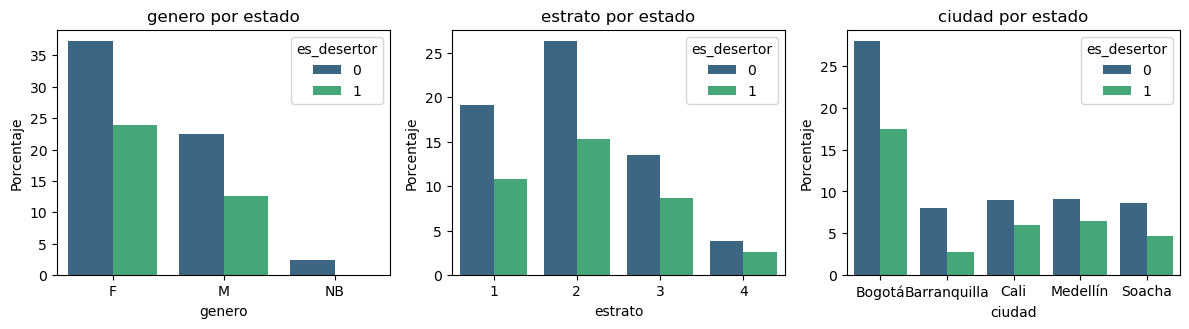

In [111]:
Demografica= ["genero", "estrato", 'ciudad']
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.flatten()

for i, col in enumerate(Demografica):
    sns.countplot(
    x=col, data=df_eda, hue='es_desertor',
    stat="percent", palette='viridis', ax=axes[i]
)
    axes[i].set_title(f"{col} por estado")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Porcentaje")


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

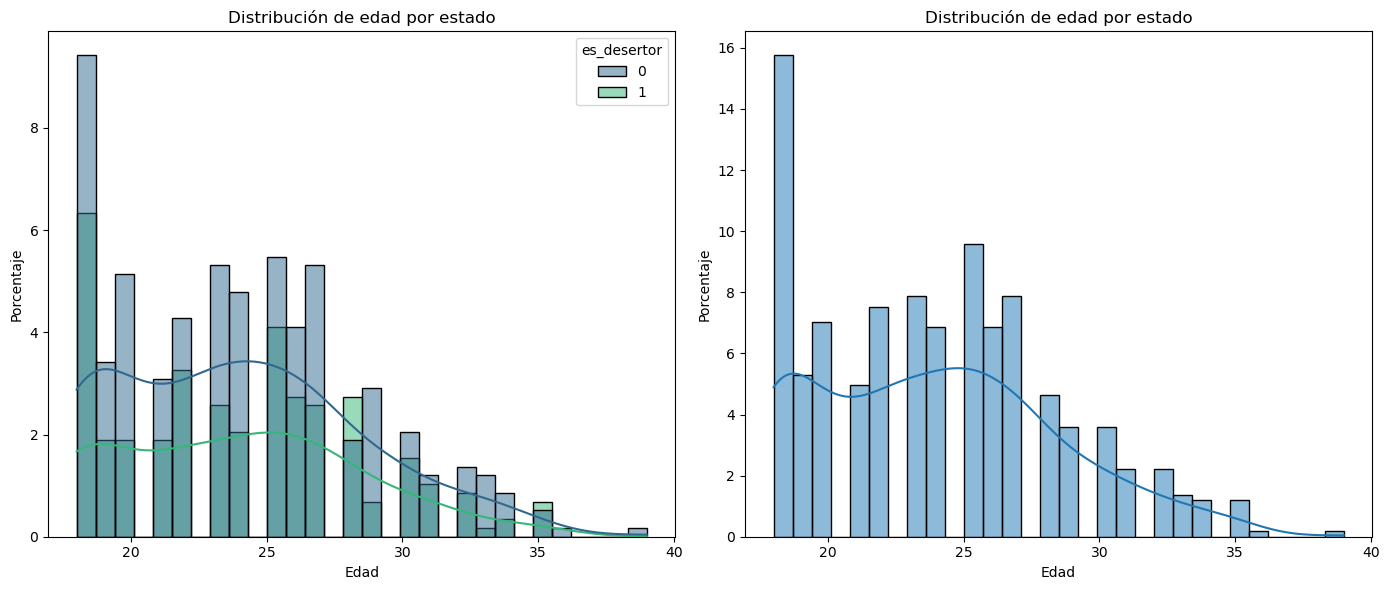

In [115]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Distribucion de edad
sns.histplot(
    data=df_eda, x='edad', hue='es_desertor',
    stat="percent", kde=True, palette='viridis', bins=30, ax=axes[0]
)
axes[0].set_title('Distribución de edad por estado')
axes[0].set_xlabel('Edad')
axes[0].set_ylabel('Porcentaje')

# General Distribution 
sns.histplot(
    data=df_eda, x='edad',
    stat="percent", kde=True, bins=30, ax=axes[1]
)
axes[1].set_title('Distribución de edad por estado')
axes[1].set_xlabel('Edad')
axes[1].set_ylabel('Porcentaje')

plt.tight_layout()
plt.show()

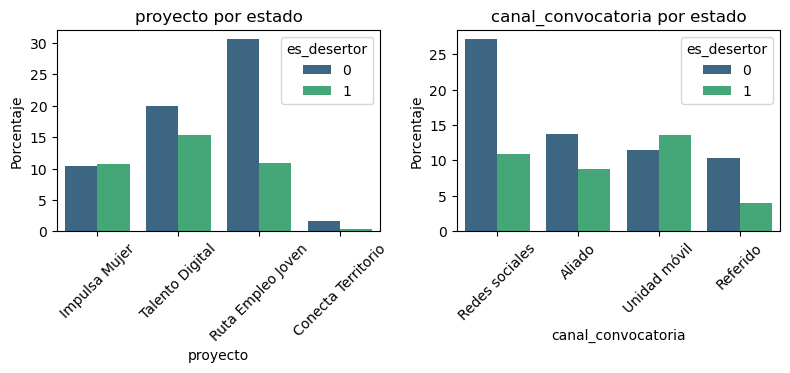

In [117]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.flatten()

for i, col in enumerate(Institucional):
    sns.countplot(
    x=col, data=df_eda, hue='es_desertor',
    stat="percent", palette='viridis', ax=axes[i]
)
    axes[i].set_title(f"{col} por estado")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Porcentaje")
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

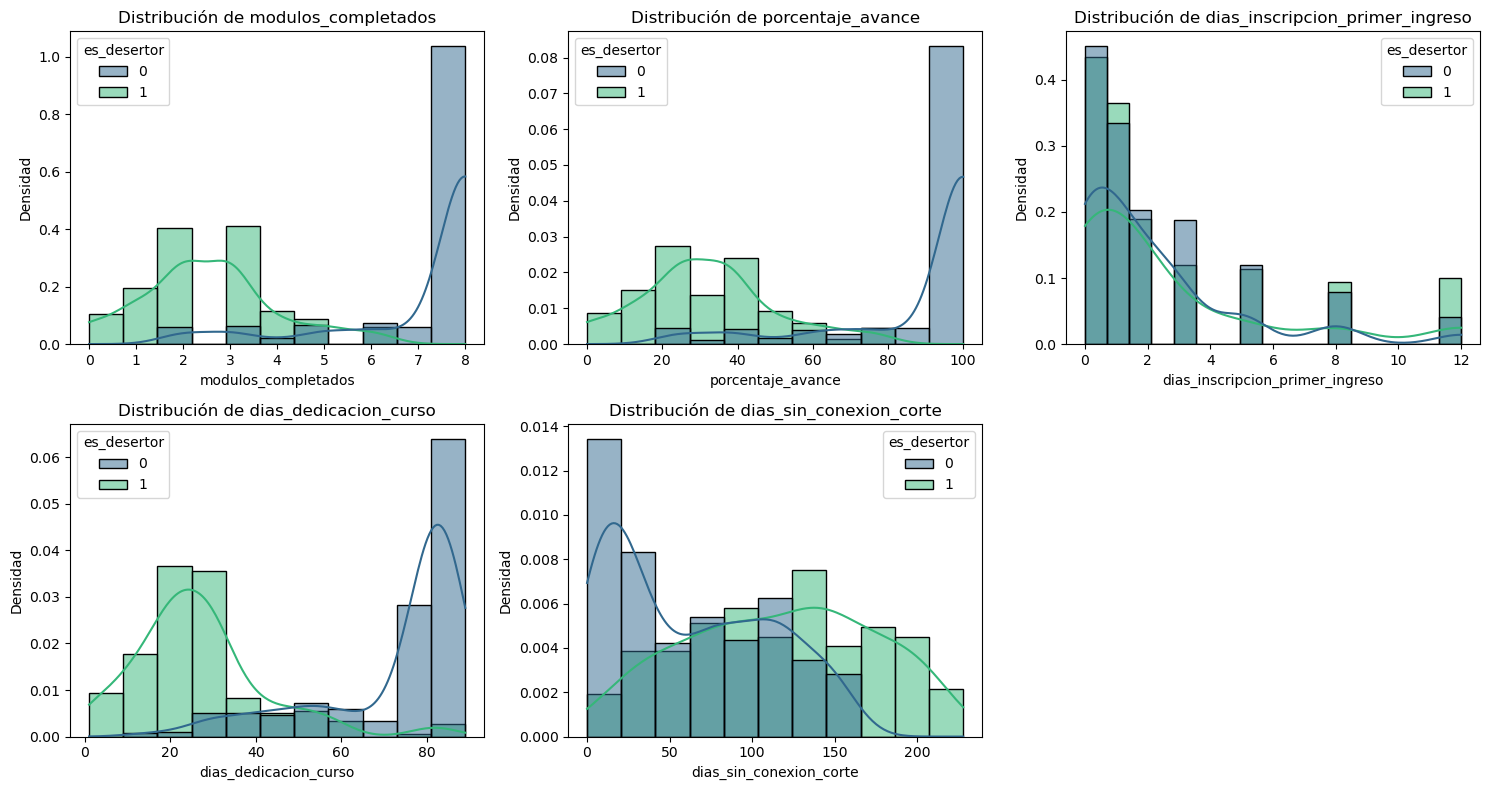

In [ ]:

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(Desempeno):

    sns.histplot(
        data=df_eda,
        x=col,
        hue='es_desertor',
        kde=True,
        stat='density',
        common_norm=False,
        palette='viridis',
        ax=axes[i]
    )

    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Densidad')

# Eliminar subplot vacío
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:

Desempeno = ["modulos_completados", "porcentaje_avance","dias_inscripcion_primer_ingreso","dias_dedicacion_curso","dias_sin_conexion_corte"
]

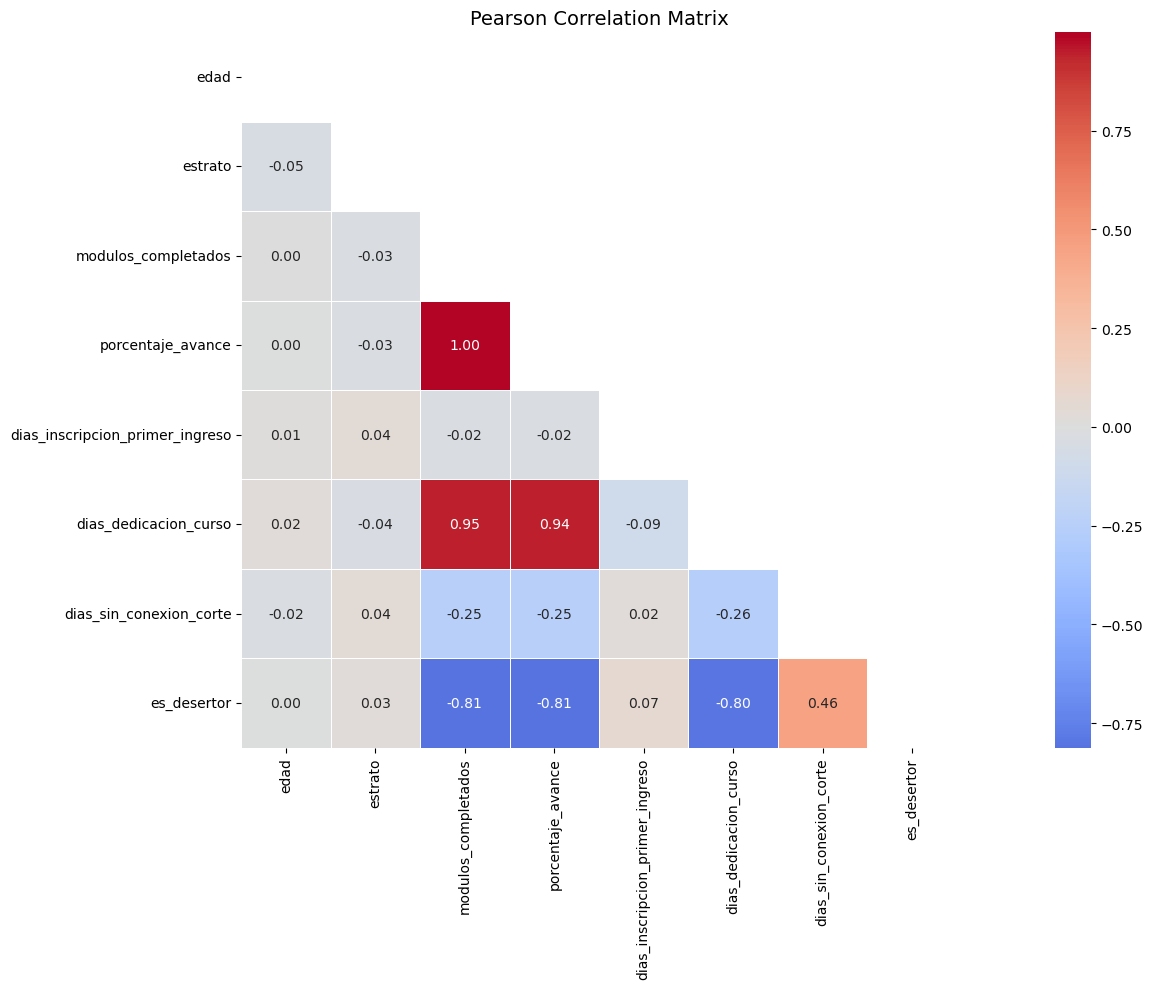

In [127]:
numeric_columns = [
    "edad", "estrato","modulos_completados", "porcentaje_avance","dias_inscripcion_primer_ingreso",
    "dias_dedicacion_curso","dias_sin_conexion_corte","es_desertor"
]

# Create masks for upper triangles
mask = np.triu(np.ones_like(df_eda[numeric_columns].corr(), dtype=bool))

fig, axes = plt.subplots(1, 1, figsize=(20, 10))

# Pearson Correlation
pearson_corr = df_eda[numeric_columns].corr(method='pearson')
sns.heatmap(
    pearson_corr, mask=mask, annot=True, fmt=".2f",
    cmap="coolwarm", center=0, linewidths=0.5, square=True
)
axes.set_title("Pearson Correlation Matrix", fontsize=14)

plt.tight_layout()
plt.show()

C:\Users\Juan N\AppData\Local\Temp\ipykernel_5988\442866006.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\Juan N\AppData\Local\Temp\ipykernel_5988\442866006.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\Juan N\AppData\Local\Temp\ipykernel_5988\442866006.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


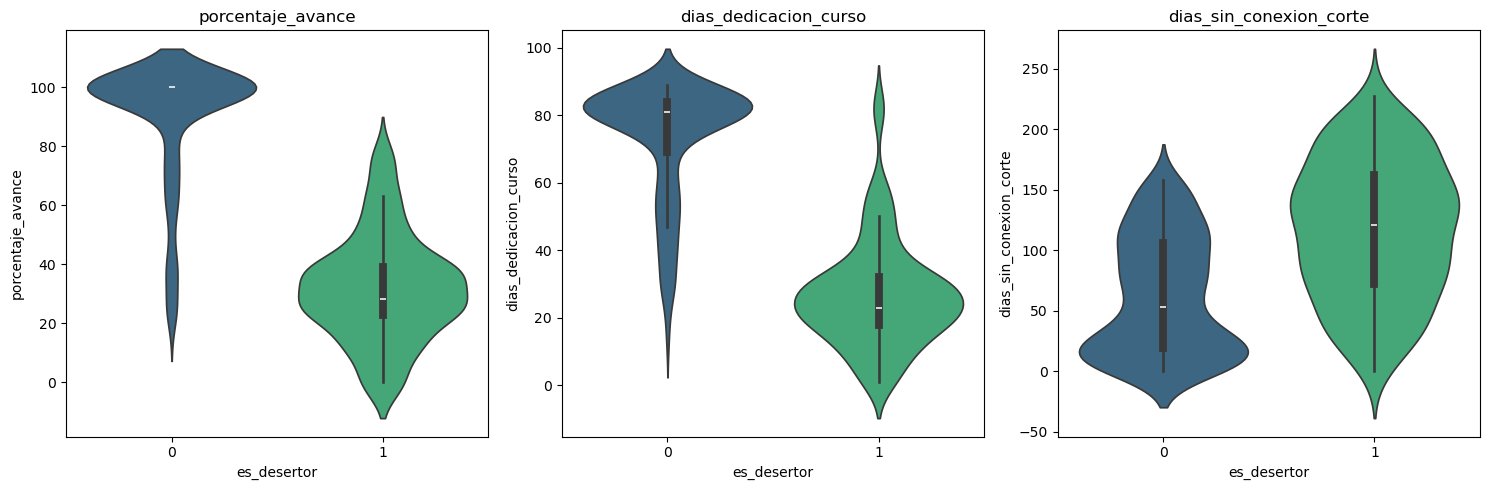

In [ ]:
variables_clave = [
    'porcentaje_avance',
    'dias_dedicacion_curso',
    'dias_sin_conexion_corte'
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, col in enumerate(variables_clave):

    sns.violinplot(
        data=df_eda,
        x='es_desertor',
        y=col,
        palette='viridis',
        ax=axes[i]
    )

    axes[i].set_title(col)

plt.tight_layout()
plt.show()

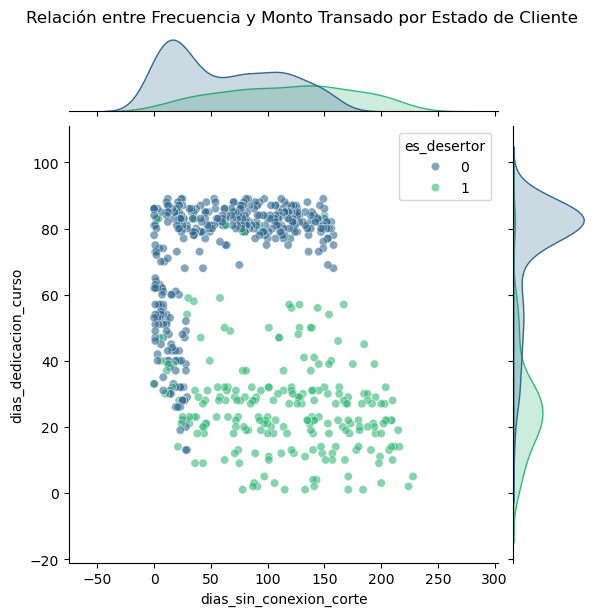

In [ ]:
sns.jointplot(data=df_eda, x='dias_sin_conexion_corte', y='dias_dedicacion_curso', hue='es_desertor', 
              kind='scatter', palette='viridis', alpha=0.6)
plt.suptitle('Relación entre dias sin conexión desde el corte y dias de dedicación', y=1.02)
plt.show()

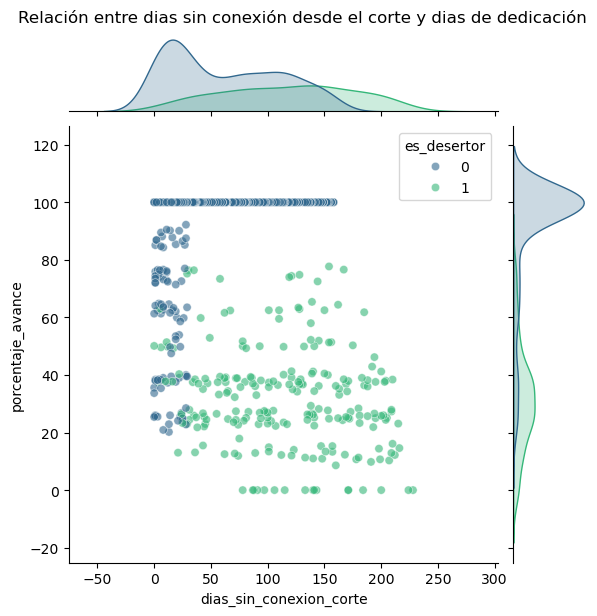

In [ ]:

sns.jointplot(data=df_eda, x='dias_sin_conexion_corte', y='porcentaje_avance', hue='es_desertor', 
              kind='scatter', palette='viridis', alpha=0.6)
plt.suptitle('Relación entre dias sin conexión desde el corte y porcentaje_avance', y=1.02)
plt.show()

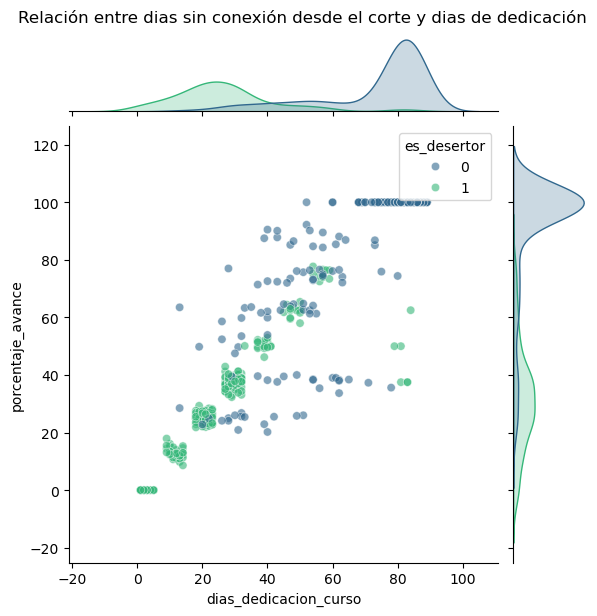

In [ ]:
variables_clave = [
    'porcentaje_avance',
    'dias_dedicacion_curso',
    'dias_sin_conexion_corte'
]
sns.jointplot(data=df_eda, x='dias_dedicacion_curso', y='porcentaje_avance', hue='es_desertor', 
              kind='scatter', palette='viridis', alpha=0.6)
plt.suptitle('Relación entre dias de dedicación y porcentaje de avance', y=1.02)
plt.show()

In [144]:
#Definición de la variable objetivo
target = df_eda["es_desertor"] == 1
#Función para el calculo de Cohen's D
def cohens_d(group1, group2):

    group1 = group1.dropna()
    group2 = group2.dropna()

    n1 = len(group1)
    n2 = len(group2)

    pooled_std = np.sqrt(
        (
            (n1 - 1) * group1.var(ddof=1)
            +
            (n2 - 1) * group2.var(ddof=1)
        )
        / (n1 + n2 - 2)
    )

    return (group1.mean() - group2.mean()) / pooled_std

In [145]:
target = df_eda['es_desertor'] == 1

desertores = df_eda.loc[target, 'porcentaje_avance']
no_desertores = df_eda.loc[~target, 'porcentaje_avance']

cohens_d(desertores, no_desertores)

np.float64(-2.8665389438185023)

In [146]:
effect_sizes = {}

for col in numeric_columns:

    if col == 'es_desertor':
        continue

    desertores = df_eda.loc[target, col]
    no_desertores = df_eda.loc[~target, col]

    effect_sizes[col] = abs(
        cohens_d(desertores, no_desertores)
    )

effect_sizes = (
    pd.Series(effect_sizes)
      .sort_values(ascending=False)
)

print(effect_sizes)

modulos_completados                2.873277
porcentaje_avance                  2.866539
dias_dedicacion_curso              2.758467
dias_sin_conexion_corte            1.058449
dias_inscripcion_primer_ingreso    0.142094
estrato                            0.059637
edad                               0.001943
dtype: float64


El análisis mediante el tamaño del efecto de Cohen evidenció que las variables porcentaje de avance, días sin conexión hasta la fecha de corte y días de dedicación al curso presentan la mayor capacidad para diferenciar entre estudiantes desertores y no desertores. Particularmente, el porcentaje de avance mostró un tamaño de efecto muy grande (d > 2), sugiriendo una fuerte separación entre ambas poblaciones.

# Modelamiento

## Construcción dataset de modelamiento

In [196]:

columnas_modelamiento= ['porcentaje_avance', 'dias_dedicacion_curso', 'dias_sin_conexion_corte', "proyecto" , "canal_convocatoria","es_desertor"]
df_modelamiento = df_eda[columnas_modelamiento]

In [197]:
# --- One-Hot Encode  ---
nominal_cols = ['proyecto', 'canal_convocatoria']
df_modelamiento = pd.get_dummies(df_modelamiento, columns=nominal_cols, drop_first=True, dtype=int)

In [198]:
df_modelamiento.head()

,porcentaje_avance,dias_dedicacion_curso,dias_sin_conexion_corte,es_desertor,proyecto_Impulsa Mujer,proyecto_Ruta Empleo Joven,proyecto_Talento Digital,canal_convocatoria_Redes sociales,canal_convocatoria_Referido,canal_convocatoria_Unidad móvil
0,100.0,78.0,158.0,0,1,0,0,1,0,0
1,100.0,75.0,158.0,0,1,0,0,1,0,0
2,100.0,68.0,158.0,0,0,0,1,1,0,0
3,100.0,82.0,156.0,0,1,0,0,0,0,0
4,100.0,89.0,149.0,0,0,1,0,1,0,0


## Train/Test 

In [199]:
# Caracteristicas y objetivo
X = df_modelamiento.drop(columns=['es_desertor'])
y = df_modelamiento['es_desertor']

# Separación estratificadoa 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,          
    random_state=42     
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [200]:
# Validation summary
print(f"Entrenamiento: {X_train_scaled.shape[0]} filas | es desertor: {y_train.mean():.1%}")
print(f"Test:  {X_test_scaled.shape[0]} filas | desertor: {y_test.mean():.1%}")

Entrenamiento: 481 filas | es desertor: 37.4%
Test:  121 filas | desertor: 37.2%


In [201]:
cv_splitter = StratifiedKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=42
)

In [202]:
scoring = {
    'recall_cv': 'recall',      # Primary: Minimize missed unsatisfied customers
    'f1_cv': 'f1',              # Secondary: Balance precision/recall tradeoff
    'roc_auc_cv': 'roc_auc'                 # Tertiary: Overall discrimination ability
}

## Modelo base regresión logística

Se establece un modelo de regresión logística que sirva como referencia de rendimiento frente a arquitecturas más complejas. El flujo de trabajo de entrenamiento y validación consta de tres pasos:

1. Evaluación de la estabilidad: Validación cruzada estratificada de 5 particiones (*5-fold*) en el conjunto de entrenamiento para evaluar el rendimiento y la varianza del modelo entre los distintos subconjuntos.

2. Ajuste de hiperparámetros: Utilizando el mismo esquema de validación cruzada estratificada de 5 particiones, se explora el espacio de parámetros para encontrar una configuración óptima.

3. Reentrenamiento final: Se entrena un modelo de referencia definitivo utilizando la totalidad del conjunto de datos de entrenamiento (el 80 % del total) y los mejores hiperparámetros hallados durante la validación cruzada.

### Validación de la estabilidad

In [203]:
lr_baseline = LogisticRegression(
    max_iter=1000,  
    random_state=50,
    solver='lbfgs'                
)

In [204]:
cv_results = cross_validate(
    lr_baseline, 
    X_train_scaled, y_train, 
    cv=cv_splitter, 
    scoring=scoring,
    return_train_score=False
)

In [205]:
cv_summary = pd.DataFrame({
    'Metrica': ['Recall ', 'F1-Score', 'ROC-AUC'],
    'CV promedio': [
        cv_results['test_recall_cv'].mean(),
        cv_results['test_f1_cv'].mean(),
        cv_results['test_roc_auc_cv'].mean()
    ],
    'CV Std': [
        cv_results['test_recall_cv'].std(),
        cv_results['test_f1_cv'].std(),
        cv_results['test_roc_auc_cv'].std()
    ]
})

In [206]:
print("---------------LOGISTIC REGRESSION: STRATIFIED 5-FOLD CV RESULTS-----------------")
print(cv_summary.to_string(index=False))

---------------LOGISTIC REGRESSION: STRATIFIED 5-FOLD CV RESULTS-----------------
 Metrica  CV promedio   CV Std
 Recall      0.911111 0.056656
F1-Score     0.924000 0.038908
 ROC-AUC     0.983807 0.010477


## Hiperparámetros

In [207]:
param_grid = [
    {
        'solver': ['lbfgs'],
        'penalty': ['l2'],
        'C': [0.001,0.01, 0.1, 1, 10, 100]
    },
    {
        'solver': ['saga'],
        'penalty': ['l1', 'l2'],
        'C': [0.001,0.01, 0.1, 1, 10, 100]
    }
]

# Inicializacion LR
lr_tune = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,
    random_state=50
)



scoring = {
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

search = GridSearchCV(
    estimator=lr_tune,
    param_grid=param_grid,
    cv=cv_splitter,
    scoring=scoring,
    refit='recall',  
    return_train_score=False,
    n_jobs=-1
)

search.fit(X_train_scaled, y_train)



,estimator,LogisticRegre...ndom_state=50)
,param_grid,"[{'C': [0.001, 0.01, ...], 'penalty': ['l2'], 'solver': ['lbfgs']}, {'C': [0.001, 0.01, ...], 'penalty': ['l1', 'l2'], 'solver': ['saga']}]"
,scoring,"{'f1': 'f1', 'recall': 'recall', 'roc_auc': 'roc_auc'}"
,n_jobs,-1
,refit,'recall'
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [208]:
best_idx = search.best_index_

cv_summary = pd.DataFrame({
    'Metrica': ['Recall', 'F1-Score', 'ROC-AUC'],
    'CV promedio': [
        search.cv_results_['mean_test_recall'][best_idx],
        search.cv_results_['mean_test_f1'][best_idx],
        search.cv_results_['mean_test_roc_auc'][best_idx]
    ],
    'CV Std': [
        search.cv_results_['std_test_recall'][best_idx],
        search.cv_results_['std_test_f1'][best_idx],
        search.cv_results_['std_test_roc_auc'][best_idx]
    ]
})

print("=== LR ===")
print(f"Mejores parametros: {search.best_params_}")
print()
print(cv_summary)

=== LR ===
Mejores parametros: {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}

    Metrica  CV promedio    CV Std
0    Recall     0.927778  0.045134
1  F1-Score     0.920705  0.039570
2   ROC-AUC     0.983066  0.011249


## Regresión Final

In [209]:
# Mejores estimadores
best_lr = search.best_estimator_
best_lr.fit(X_train_scaled, y_train)

# Predicción sobre el set
y_pred_final = best_lr.predict(X_test_scaled)
y_prob_final = best_lr.predict_proba(X_test_scaled)[:, 1]

In [210]:
print("---------------LR FINAL-----------------")
print(classification_report(y_test, y_pred_final, target_names=['Desertor', 'No Desertor']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_final):.4f}")

# Matriz de confución 
cm = confusion_matrix(y_test, y_pred_final)

print(f"True Negatives (No desertores correctamente identificados): {cm[0,0]}")
print(f"False Positives (No desertores clasificados como desertores): {cm[0,1]}")
print(f"False Negatives (Desertores no detectados): {cm[1,0]}")
print(f"True Positives (Desertores correctamente detectados): {cm[1,1]}")

---------------LR FINAL-----------------
              precision    recall  f1-score   support

    Desertor       0.92      0.92      0.92        76
 No Desertor       0.87      0.87      0.87        45

    accuracy                           0.90       121
   macro avg       0.89      0.89      0.89       121
weighted avg       0.90      0.90      0.90       121

ROC-AUC Score: 0.9787
True Negatives (No desertores correctamente identificados): 70
False Positives (No desertores clasificados como desertores): 6
False Negatives (Desertores no detectados): 6
True Positives (Desertores correctamente detectados): 39


In [211]:
joblib.dump(best_lr, LR_MODEL)

['c:\\Prueba tecnica\\KUEPA\\Prueba Tecnica\\models\\lr_best_model.pkl']

# Interpretación

In [212]:
# Coeficientes del modelo
coef_df = pd.DataFrame({
    'Caracteristica': X.columns,
    'Coeficiente': best_lr.coef_[0],
    'Odds_Ratio': np.exp(best_lr.coef_[0])
}).sort_values('Coeficiente', ascending=False)

print("TOP FACTORES ASOCIADOS A LA DESERCIÓN")
print(coef_df.sort_values('Coeficiente', ascending=False).head(10).to_string(index=False))

print("TOP FACTORES ASOCIADOS A LA PERMANENCIA")
print(coef_df.sort_values('Coeficiente', ascending=True).head(10).to_string(index=False))

TOP FACTORES ASOCIADOS A LA DESERCIÓN
                   Caracteristica  Coeficiente  Odds_Ratio
          dias_sin_conexion_corte     2.227193    9.273798
       proyecto_Ruta Empleo Joven     0.718896    2.052165
         proyecto_Talento Digital     0.685897    1.985551
           proyecto_Impulsa Mujer     0.252501    1.287241
  canal_convocatoria_Unidad móvil     0.120316    1.127854
canal_convocatoria_Redes sociales     0.014098    1.014198
      canal_convocatoria_Referido    -0.173785    0.840478
            dias_dedicacion_curso    -1.124916    0.324680
                porcentaje_avance    -3.248172    0.038845
TOP FACTORES ASOCIADOS A LA PERMANENCIA
                   Caracteristica  Coeficiente  Odds_Ratio
                porcentaje_avance    -3.248172    0.038845
            dias_dedicacion_curso    -1.124916    0.324680
      canal_convocatoria_Referido    -0.173785    0.840478
canal_convocatoria_Redes sociales     0.014098    1.014198
  canal_convocatoria_Unidad móvil    

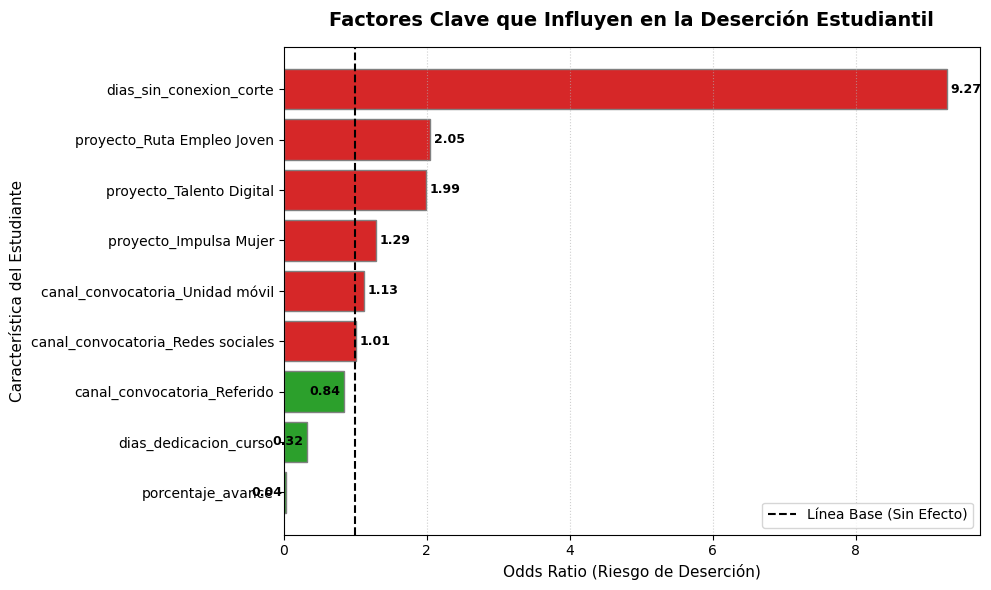

In [214]:


# Calcular el impacto absoluto (distancia desde la neutralidad OR=1)
coef_df['Impact'] = np.abs(coef_df['Odds_Ratio'] - 1)

# Seleccionar las Top 10
top_features = coef_df.sort_values('Impact', ascending=False).head(10)

# Ordenar por Odds Ratio 
top_features = top_features.sort_values('Odds_Ratio', ascending=True)


colors = ['#d62728' if x > 1 else '#2ca02c' for x in top_features['Odds_Ratio']]

#  Generar la gráfica
plt.figure(figsize=(10, 6))
bars = plt.barh(top_features['Caracteristica'], top_features['Odds_Ratio'], color=colors, edgecolor='grey')

# Línea de base (OR = 1 significa que la variable no afecta la probabilidad)
plt.axvline(x=1.0, color='black', linestyle='--', linewidth=1.5, label='Línea Base (Sin Efecto)')

# Etiquetas y Títulos
plt.grid(axis='x', linestyle=':', alpha=0.6, zorder=0)
plt.title('Factores Clave que Influyen en la Deserción Estudiantil', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Odds Ratio (Riesgo de Deserción)', fontsize=11)
plt.ylabel('Característica del Estudiante', fontsize=11)

# Añadir etiquetas de valor en las barras para mayor claridad
for bar in bars:
    width = bar.get_width()
    label_x_pos = width + 0.05 if width > 1 else width - 0.05
    ha = 'left' if width > 1 else 'right'
    plt.text(label_x_pos, bar.get_y() + bar.get_height()/2, f'{width:.2f}', 
             va='center', ha=ha, fontsize=9, fontweight='bold')

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()